![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# ET at Other Resolutions: MODIS, Sentinel-3 and Sentinel-2 with Thermal Sharpening

Landsat's 30 m reflectance and 100 m thermal band (delivered at 30 m) resolve individual fields,
but a clear Landsat image comes at most every 8 days, and clouds remove many of them. Sensors with
daily thermal coverage, MODIS and Sentinel-3 SLSTR, see every pixel every day at about 1 km.
Sentinel-2 sees every field at 10 to 20 m every 5 days but has no thermal band at all. This notebook
runs METRIC on MODIS at 1 km and compares it with Landsat, then combines Sentinel-3 temperature
with Sentinel-2 reflectance: a data mining sharpener learns the relation between reflectance and
temperature at 1 km and applies it at 20 m, giving field-scale ET on a day without a Landsat pass.

## Overview

### Space and time

| Sensor | Thermal pixel | Revisit | Overpass (local) | Role |
|---|---|---|---|---|
| Landsat 8 and 9 | 100 m (30 m product) | 8 days with both | about 10:30 to 11:30 | field-scale SEB |
| MODIS Terra and Aqua | 1 km | daily (twice) | about 10:30 and 13:30 | regional SEB, MOD16 ET product |
| Sentinel-3 SLSTR (A and B) | 1 km | daily | about 10:00 | daily thermal for sharpening |
| Sentinel-2 MSI (A, B, C) | none | 5 days | about 10:30 | 10 to 20 m reflectance |
| ECOSTRESS (on the ISS) | 70 m | irregular, varying time | any time | diurnal sampling |

The 1 km sensors average a whole section of land: on the Westside, one MODIS pixel can hold an
irrigated orchard, a fallow field and a road. Anchor pixels at 1 km are therefore less pure than at
30 m, and the extremes of the LST and NDVI scatter shrink.

### Thermal sharpening

Thermal sharpening (Kustas et al. 2003; Gao et al. 2012) uses the fact that at any one time and
place LST is largely explained by surface properties that a finer sensor sees: vegetation cover,
moisture (shortwave infrared) and brightness. The data mining sharpener (DMS) of Gao et al.:

1. Aggregates the fine reflectance bands to the coarse thermal grid.
2. Fits a regression (decision tree, random forest or boosting) between coarse LST and the
   aggregated bands, using the most homogeneous coarse pixels, where the relation is cleanest.
3. Applies the regression to the fine bands to predict fine LST.
4. Adds back the coarse residual (observed minus aggregated prediction), so the sharpened image
   averages exactly to the observed coarse LST (energy conservation).

The sharpened LST is a statistical estimate: it cannot recover temperature contrasts that the
reflectance does not explain, such as two identical green fields under different irrigation.

### MOD16

MODIS also has its own ET product, MOD16 (Mu et al. 2011), a Penman-Monteith model with surface
conductances from LAI and weather, published every 8 days and yearly at 500 m. It uses no thermal
band; notebook 11 compares its annual total with Landsat.

## Other Sensors with GeoLattice

| Function | Purpose |
|---|---|
| `sd.modis_1km` | MOD11A1 LST, MCD43A4 nadir reflectance, MCD15A2H LAI and elevation on a 1 km grid |
| `sd.sentinel2_20m`, `sd.sentinel3_lst_folder` | Sentinel-2 L2A at 20 m and the SLSTR LST files |
| `geolattice.rsense.optical.sensors.sentinel3` | `read_slstr_lst`, `slstr_lst_mask`, `swath_to_grid` |
| `seb.albedo(..., sensor="modis" or "sentinel2")` | broadband albedo for each sensor |
| `seb.aggregate_lst`, `seb.thermal_sharpen` | aggregation in emitted power and the data mining sharpener |
| `seb.run_metric` | METRIC at any resolution |

### Learning objectives

1. Compare the thermal sensors by pixel size, revisit and overpass time.
2. Run METRIC on MODIS at 1 km and compare it with Landsat METRIC averaged to 1 km.
3. Put a Sentinel-3 swath on a grid that nests a Sentinel-2 grid exactly.
4. Sharpen thermal data with the data mining sharpener and test it honestly on degraded Landsat.
5. Map field-scale ET from Sentinel-2 and sharpened Sentinel-3 on a day without a Landsat pass, and
   compare it with the next day's Landsat ETrF.

### Data

| Dataset | Content |
|---|---|
| MODIS Terra MOD11A1, day 187 (5 July 2024) | daytime LST, view time and QC, 1 km |
| MCD43A4 day 187 and MCD15A2H days 185 to 192 | nadir BRDF-adjusted reflectance (500 m) and LAI (500 m) |
| Sentinel-2B L2A, 4 July 2024 18:39 UTC, tile 10SGF | six bands at 20 m with the scene classification |
| Sentinel-3B SLSTR L2 LST, 4 July 2024 18:26 UTC | 1 km LST swath with flags and geolocation |
| Landsat 8 C2 L2, 5 July 2024, and its METRIC result | the reference at 30 m (`sd.load_scene`, notebook 06) |
| ERA5 hourly and daily | weather at each overpass |

MODIS uses a larger regional window (120.6 to 119.6 W, 36.0 to 36.9 N, about 90 x 100 km) so that
the 1 km anchor search finds pure enough pixels; comparisons are made inside the Landsat window.

### Contents

- Setup
- MODIS at 1 km
- METRIC on MODIS
- MODIS against Landsat
- Testing the sharpener on Landsat
- Sentinel-3 LST on a grid that nests Sentinel-2
- Sharpening Sentinel-3 with Sentinel-2
- ET at 20 m without a Landsat pass
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

from pyproj import Transformer  # coordinate transformations
from rasterio.enums import Resampling  # resampling methods
from scipy.ndimage import zoom  # bilinear upsampling for a baseline
from geolattice.rsense.optical.sensors import sentinel3 as s3  # Sentinel-3 readers

SITE = sd.WESTSIDE  # Landsat window
LAT, LON = SITE["lat"], SITE["lon"]  # scene centre for sun angles and weather
landsat = sd.load_scene()  # Landsat 8, 5 July 2024
path = OUT / "metric_20240705.nc"  # METRIC result of notebook 06
metric = xr.open_dataset(path).load() if path.exists() else sd.run_metric_scene(landsat)  # read or recompute
metric = metric.rio.write_crs(landsat.rio.crs)  # same UTM 11N grid as the Landsat stack
ref_daily = sd.daily_reference(SITE, "2024-01-01", "2024-12-31")  # daily ERA5 reference ET of 2024


def metric_chain(lst, ndvi, albedo, lai, dem, when, mask, etr_daily):  # METRIC from any sensor's layers
    wx = seb.interpolate_weather(sd.weather(SITE, f"{when:%Y-%m-%d}", f"{when:%Y-%m-%d}")["hourly"], when)  # ERA5 at the overpass
    ea = float(seb.actual_vapour_pressure(t_dew_c=wx["dew_point_2m"]))  # kPa
    u2 = float(seb.wind_2m(wx["wind_speed_10m"], 10))  # m/s
    z = float(dem.median())  # m
    etr_h = float(seb.asce_pm_hourly(wx["temperature_2m"], ea, wx["shortwave_radiation"] * 0.0036, u2, z, LAT, LON, when, reference="tall"))  # mm/h
    cos_t = float(np.cos(np.radians(seb.solar_position(LAT, LON, when)["zenith"])))  # flat ground
    P = seb.pressure_from_elevation(dem)  # kPa
    tau = seb.broadband_transmissivity(cos_t, pressure=P, ea=ea)  # transmissivity
    e0 = seb.surface_emissivity(lai, ndvi)  # broadband emissivity
    anchors = seb.select_anchors(ndvi, lst, albedo_=albedo, mask=mask)  # hot and cold pixels
    rl_in = seb.incoming_longwave(anchors["cold"]["lst"], seb.air_emissivity(tau_sw=float(tau.median())))  # W/m2
    rn = seb.net_radiation(seb.incoming_shortwave(cos_t, tau, dr=float(seb.inverse_relative_distance(when.day_of_year))),
                           albedo, rl_in, seb.outgoing_longwave(lst, e0), e0)  # W/m2
    g = seb.soil_heat_flux(rn, lst, lai=lai, method="metric", ndvi_=ndvi)  # W/m2
    res = seb.run_metric(lst, rn, g, seb.momentum_roughness(lai=lai), float(seb.wind_at_blending_height(u2)), P, etr_h,
                         anchors=anchors, etr_daily=etr_daily)  # METRIC
    return res, anchors, etr_h  # result, anchors and overpass ETr

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## MODIS at 1 km

`sd.modis_1km` reprojects the Terra daytime LST (nearest), the nadir reflectance and LAI (averaged
from 500 m) and the elevation onto a 1 km UTM grid. `QC_Day` bits 0 and 1 equal to 0 mark LST of
good quality. `Day_view_time` is the local solar time of the observation.

{'y': 103, 'x': 94} | good pixels 82% | Terra view at 9.9 h local solar time = 17:54 UTC (Landsat: 18:33 UTC)


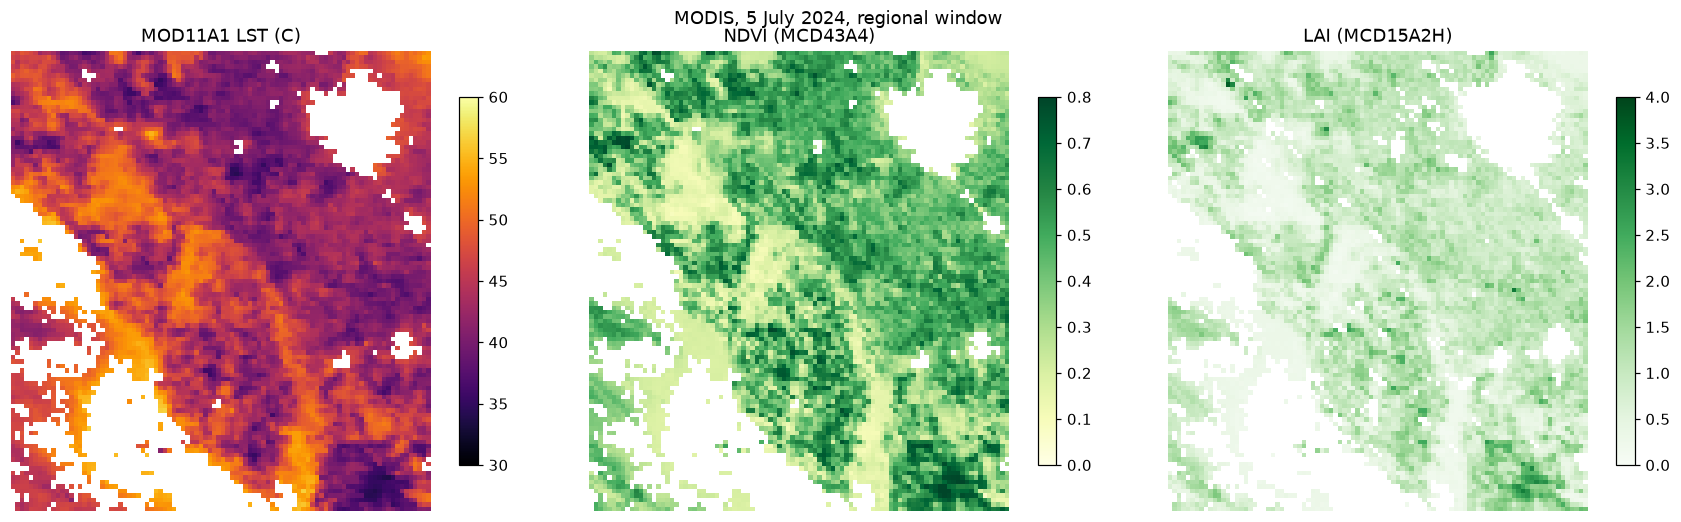

In [2]:
mo = sd.modis_1km("2024-07-05")  # MODIS inputs, 1 km
good = ((mo.qc.fillna(255).astype(int) & 3) == 0) & mo.lst.notnull() & mo.red.notnull()  # good quality LST and reflectance
solar_h = float(mo.view_time.where(good).median())  # local solar time of the view, hours
when_m = pd.Timestamp("2024-07-05") + pd.Timedelta(hours=solar_h - LON / 15)  # approximate UTC time of the observation
print(dict(mo.sizes), f"| good pixels {float(good.mean()):.0%} | Terra view at {solar_h:.1f} h local solar time = {when_m:%H:%M} UTC "
      f"(Landsat: {pd.Timestamp(landsat.attrs['datetime']):%H:%M} UTC)")  # grid and time
ndvi_m = seb.ndvi(mo.red, mo.nir).where(good)  # NDVI from nadir reflectance
alb_m = seb.albedo(mo, sensor="modis").where(good)  # Liang (2001) MODIS weights
lst_m = mo.lst.where(good)  # K
dem_m = mo.dem.fillna(float(mo.dem.median()))  # elevation (corners of the UTM grid outside the DEM tiles filled)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))  # three maps
for a_, v, cm, lim, t in [(ax[0], lst_m - 273.15, "inferno", (30, 60), "MOD11A1 LST (C)"), (ax[1], ndvi_m, "YlGn", (0, 0.8), "NDVI (MCD43A4)"),
                          (ax[2], mo.lai.where(good), "Greens", (0, 4), "LAI (MCD15A2H)")]:  # three layers
    im = a_.imshow(v, cmap=cm, vmin=lim[0], vmax=lim[1]); plt.colorbar(im, ax=a_, shrink=0.8); a_.set_title(t); a_.axis("off")  # map
plt.suptitle("MODIS, 5 July 2024, regional window"); plt.tight_layout(); plt.show()  # draw

At 1 km the field pattern disappears into blocks, but the gradient from the irrigated valley in the
east to the dry rangeland and foothills in the west remains.

## METRIC on MODIS

The same METRIC chain as for Landsat, with MODIS LAI from MCD15A2H instead of SAVI, the MODIS
albedo weights, and the ERA5 weather and hourly ETr at the Terra overpass.

ETr at the Terra overpass 0.83 mm/h | converged after 5 iterations


ndvi   lst_c  albedo  n_candidates
             anchor                                     
MODIS 1 km   cold    0.702  35.470   0.188            74
             hot     0.153  53.350   0.252           157
Landsat 30 m cold    0.832  35.236   0.191          3636
             hot     0.109  60.037   0.185         11899

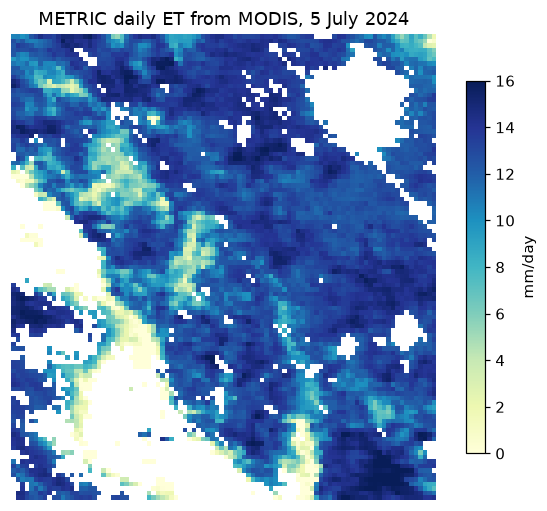

In [3]:
res_m, anc_m, etr_m = metric_chain(lst_m, ndvi_m, alb_m, mo.lai.where(good), dem_m, when_m, good, ref_daily.loc["2024-07-05", "etr"])  # METRIC on MODIS
print(f"ETr at the Terra overpass {etr_m:.2f} mm/h | converged after {res_m.attrs['iterations']} iterations")  # calibration
anc = seb.anchor_report(anc_m)  # MODIS anchors
anc["lst_c"] = anc.lst - 273.15  # C
display(pd.concat({"MODIS 1 km": anc[["ndvi", "lst_c", "albedo", "n_candidates"]],
                   "Landsat 30 m": seb.anchor_report(sd.energy_inputs(landsat)["anchors"]).assign(lst_c=lambda d: d.lst - 273.15)[["ndvi", "lst_c", "albedo", "n_candidates"]]}).round(3))  # anchors at both scales
fig, ax = plt.subplots(figsize=(7, 5.5)); im = ax.imshow(res_m.et24, cmap="YlGnBu", vmin=0, vmax=16)  # daily ET
plt.colorbar(im, ax=ax, shrink=0.8, label="mm/day"); ax.set_title("METRIC daily ET from MODIS, 5 July 2024"); ax.axis("off"); plt.show()  # draw

At 1 km the anchors are less extreme. The cold anchor has nearly the same LST as Landsat's (35.5
against 35.2 C, Terra looked 40 minutes earlier) but an NDVI of only 0.70: it is a mixture of
fields. The hot anchor is 6.7 K cooler than Landsat's bare field (53.4 against 60.0 C). The
calibration spans 18 K instead of 25 K.

## MODIS against Landsat

Landsat METRIC daily ET of the same day, averaged over each MODIS cell inside the Landsat window,
is the comparison.

785 cells: Landsat mean 8.25 mm, MODIS mean 11.39 mm, bias +3.14 mm, RMSE 4.31 mm, R2 0.53


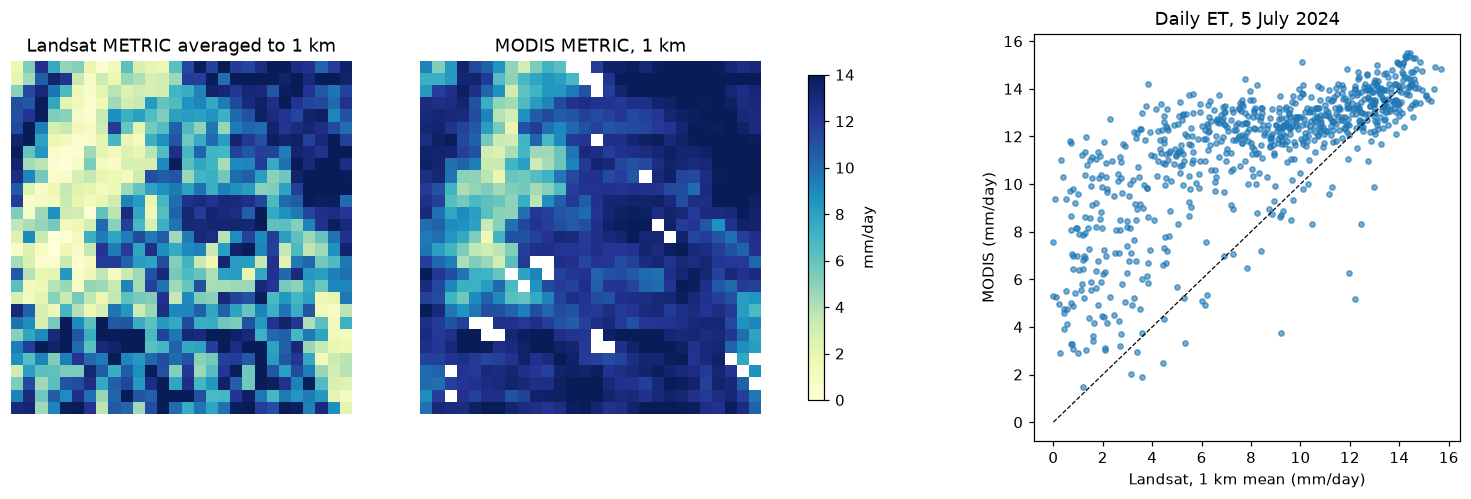

In [4]:
ls_1km = metric.et24.rio.reproject_match(mo.lst, resampling=Resampling.average)  # Landsat daily ET averaged to the MODIS grid
inside = ls_1km.notnull() & res_m.et24.notnull()  # cells inside the Landsat window
stats = seb.compare_to_tower(res_m.et24.where(inside), ls_1km.where(inside))  # MODIS against Landsat
print(f"{int(stats.n)} cells: Landsat mean {stats.mean_obs:.2f} mm, MODIS mean {stats.mean_pred:.2f} mm, bias {stats.bias:+.2f} mm, "
      f"RMSE {stats.rmse:.2f} mm, R2 {stats.r2:.2f}")  # agreement
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))  # three panels
win = dict(x=slice(float(ls_1km.x[inside.any("y")].min()), float(ls_1km.x[inside.any("y")].max())),
           y=slice(float(ls_1km.y[inside.any("x")].max()), float(ls_1km.y[inside.any("x")].min())))  # the Landsat window
for a_, v, t in [(ax[0], ls_1km.sel(**win), "Landsat METRIC averaged to 1 km"), (ax[1], res_m.et24.where(inside).sel(**win), "MODIS METRIC, 1 km")]:  # two maps
    im = a_.imshow(v, cmap="YlGnBu", vmin=0, vmax=14); a_.set_title(t); a_.axis("off")  # map
plt.colorbar(im, ax=ax[:2], shrink=0.8, label="mm/day")  # shared scale
ax[2].scatter(ls_1km.where(inside).values.ravel(), res_m.et24.where(inside).values.ravel(), s=12, alpha=0.6); ax[2].plot([0, 14], [0, 14], "k--", lw=0.8)  # scatter
ax[2].set_xlabel("Landsat, 1 km mean (mm/day)"); ax[2].set_ylabel("MODIS (mm/day)"); ax[2].set_title("Daily ET, 5 July 2024"); plt.show()  # labels

MODIS reproduces the broad pattern of the Landsat result (R2 0.53 over 785 cells) but is 3.1 mm/day
higher on average. The anchors explain most of it: METRIC assigns 1.05 ETr to the cold anchor, and
at 1 km that pixel is a mixture with bare ground in it that cannot evaporate that much; every cell
calibrated against it inherits the excess, and the cooler hot anchor narrows the range further. The
inputs add to the difference (a different LST algorithm and view time, 8 day LAI, 16 day BRDF
reflectance). For water accounting at the scale of irrigation districts MODIS is useful once its
calibration is checked against a finer sensor; for individual fields it is not.

## Testing the sharpener on Landsat

The honest way to test a sharpener is to degrade an image whose truth is known. The 30 m Landsat LST
is aggregated to 990 m (33 x 33 pixels, averaging emitted power), sharpened back to 30 m with the
Landsat reflectance, and compared with the original. Bilinear interpolation of the 990 m image is the
baseline the sharpener must beat.

,RMSE (K),bias (K),R2
bilinear 990 m,4.512,0.175,0.613
DMS random forest,2.303,0.083,0.909


largest difference between the sharpened image averaged to 990 m and the coarse LST: 0.000 K


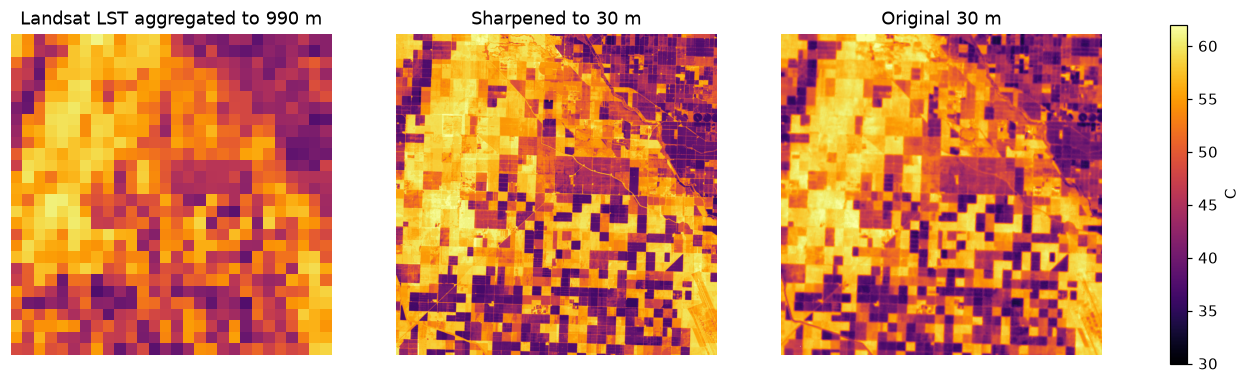

In [5]:
m = landsat.clear.astype(bool)  # clear pixels
n = 33 * (min(landsat.sizes["y"], landsat.sizes["x"]) // 33)  # crop to whole 33 x 33 blocks
L = landsat.isel(y=slice(0, n), x=slice(0, n))  # cropped stack
truth = L.lst.where(L.clear.astype(bool))  # 30 m LST, K
coarse = seb.aggregate_lst(truth, 33)  # 990 m LST, emitted-power mean
fine = L[list(sd.REFLECTANCE)].assign(ndvi=seb.ndvi(L.red, L.nir))  # 30 m predictors: six bands and NDVI
sharp = seb.thermal_sharpen(coarse, fine, factor=33, model="forest", smooth_residuals=False, random_state=0)  # data mining sharpener
bilinear = xr.DataArray(zoom(coarse.values, 33, order=1, mode="nearest")[:n, :n], coords=truth.coords, dims=truth.dims)  # baseline
rows = {}  # accuracy table
for name, est in [("bilinear 990 m", bilinear), ("DMS random forest", sharp)]:  # both estimates
    s_ = seb.compare_to_tower(est, truth)  # against the 30 m truth
    rows[name] = {"RMSE (K)": s_.rmse, "bias (K)": s_.bias, "R2": s_.r2}  # metrics
display(pd.DataFrame(rows).T.round(3))  # table
print(f"largest difference between the sharpened image averaged to 990 m and the coarse LST: "
      f"{float(np.nanmax(np.abs(seb.aggregate_lst(sharp, 33, emissive=False) - coarse))):.3f} K")  # residual correction conserves the coarse LST
fig, ax = plt.subplots(1, 3, figsize=(16, 5))  # three maps
for a_, v, t in zip(ax, [coarse, sharp, truth], ["Landsat LST aggregated to 990 m", "Sharpened to 30 m", "Original 30 m"]):  # three images
    im = a_.imshow(v - 273.15, cmap="inferno", vmin=30, vmax=62); a_.set_title(t); a_.axis("off")  # map
plt.colorbar(im, ax=ax, shrink=0.8, label="C"); plt.show()  # shared scale

The sharpener restores the field pattern that bilinear interpolation cannot: RMSE falls from 4.5 K
to 2.3 K and R2 rises from 0.61 to 0.91. What remains is mostly within-field variation and contrasts
that the reflectance does not explain. With the unsmoothed residual correction, the sharpened image
averages back exactly to the coarse LST.

## Sentinel-3 LST on a grid that nests Sentinel-2

The SLSTR LST product is a swath with a latitude and longitude for every pixel. The 20 m Sentinel-2
window is cut to whole 50 x 50 pixel blocks, so a 1 km grid with the same origin nests exactly.
The swath coordinates are projected to the Sentinel-2 UTM zone (10N) and the valid LST is placed on
that 1 km grid by nearest neighbour.

In [6]:
s2 = sd.sentinel2_20m()  # Sentinel-2B L2A, 4 July 2024, 20 m, UTM 10N
folder = sd.sentinel3_lst_folder()  # SLSTR LST files (about 10 MB)
when3 = pd.Timestamp((folder / "datetime.txt").read_text())  # SLSTR acquisition time, UTC
lst3 = s3.read_slstr_lst(folder)  # LST, uncertainty, flags, lon/lat
valid = s3.slstr_lst_mask(lst3)  # no cloud
to10 = Transformer.from_crs(4326, s2.rio.crs, always_xy=True)  # lon/lat -> UTM 10N
xx, yy = to10.transform(lst3.longitude.values, lst3.latitude.values)  # swath coordinates in metres
xx = xr.DataArray(xx, dims=lst3.LST.dims); yy = xr.DataArray(yy, dims=lst3.LST.dims)  # as DataArrays
bounds = (float(s2.x.min()) - 10, float(s2.y.min()) - 10, float(s2.x.max()) + 10, float(s2.y.max()) + 10)  # outer edges of the 20 m window
lst_1km = s3.swath_to_grid(lst3.LST.where(valid), xx, yy, resolution=1000.0, bounds=bounds, crs=s2.rio.crs,
                           method="nearest", max_distance=750.0)  # SLSTR LST on the 1 km grid
print(f"Sentinel-2 at {pd.Timestamp(s2.attrs['datetime']):%H:%M} UTC, SLSTR at {when3:%H:%M} UTC, 4 July 2024")  # times
print(f"20 m grid {dict(s2.sizes)} -> 1 km grid {dict(lst_1km.sizes)}; valid 1 km cells: {int(lst_1km.notnull().sum())}")  # grids

Sentinel-2 at 18:39 UTC, SLSTR at 18:26 UTC, 4 July 2024
20 m grid {'y': 1400, 'x': 1350} -> 1 km grid {'y': 28, 'x': 27}; valid 1 km cells: 756


## Sharpening Sentinel-3 with Sentinel-2

The same sharpener now learns from 756 Sentinel-3 cells and the Sentinel-2 bands averaged over them,
and predicts LST for every 20 m pixel. Here the residual is smoothed bilinearly before it is added
back: the unsmoothed residual conserves the 1 km LST exactly but leaves visible 1 km block edges,
while the smoothed one gives up a little of that conservation for a better 20 m pattern. Landsat LST of the next day (5 July, 18:33 UTC), reprojected
to the 20 m grid, gives an independent check of the pattern; a bias between the two is expected,
since the days, times and LST algorithms differ.

,R2 with Landsat,bias (K),RMSE (K)
"Sentinel-3, 1 km blocks",0.495,-0.612,5.193
Sentinel-3 sharpened to 20 m,0.817,-0.586,3.159


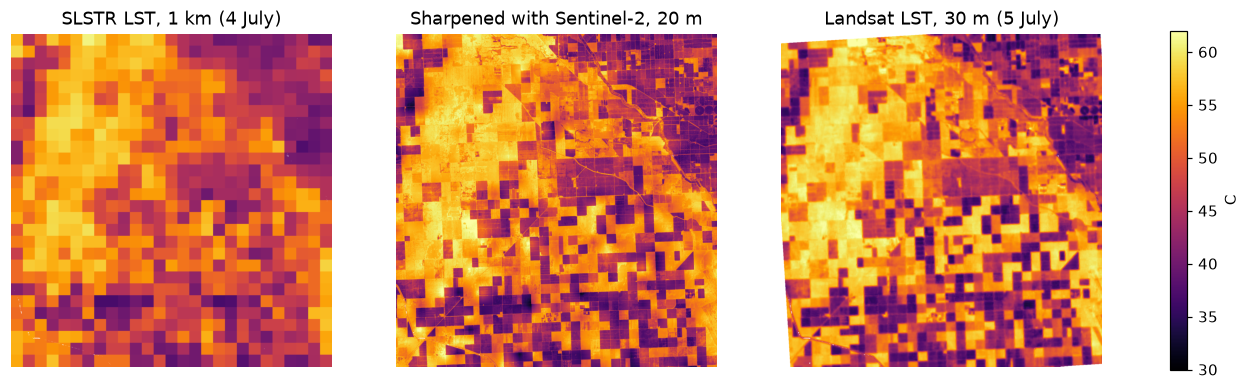

In [7]:
m2 = s2.clear.astype(bool) & (s2.water == 0)  # clear land pixels
pred2 = s2[list(sd.REFLECTANCE)].where(m2).assign(ndvi=seb.ndvi(s2.red, s2.nir).where(m2))  # 20 m predictors
lst_s2 = seb.thermal_sharpen(lst_1km, pred2, factor=50, model="forest", smooth_residuals=True, random_state=0)  # 20 m LST, K (smoothed residual)
ls_on_s2 = landsat.lst.where(landsat.clear.astype(bool)).rio.reproject_match(s2.red, resampling=Resampling.bilinear)  # Landsat LST on the 20 m grid
near = xr.DataArray(np.kron(lst_1km.values, np.ones((50, 50))), coords=s2.red.coords, dims=s2.red.dims)  # 1 km LST repeated at 20 m
rows = {}  # agreement with Landsat
for name, est in [("Sentinel-3, 1 km blocks", near), ("Sentinel-3 sharpened to 20 m", lst_s2)]:  # both estimates
    s_ = seb.compare_to_tower(est.where(m2), ls_on_s2)  # against next-day Landsat
    rows[name] = {"R2 with Landsat": s_.r2, "bias (K)": s_.bias, "RMSE (K)": s_.rmse}  # metrics
display(pd.DataFrame(rows).T.round(3))  # table
fig, ax = plt.subplots(1, 3, figsize=(16, 5))  # three maps
for a_, v, t in zip(ax, [near, lst_s2, ls_on_s2], ["SLSTR LST, 1 km (4 July)", "Sharpened with Sentinel-2, 20 m", "Landsat LST, 30 m (5 July)"]):  # three images
    im = a_.imshow(v.where(m2) - 273.15, cmap="inferno", vmin=30, vmax=62); a_.set_title(t); a_.axis("off")  # map
plt.colorbar(im, ax=ax, shrink=0.8, label="C"); plt.show()  # shared scale

The sharpened map has the field structure of the Landsat image: R2 with next-day Landsat rises from
0.50 for the 1 km blocks to 0.82 at 20 m, and RMSE falls from 5.2 K to 3.2 K. The bias of about -0.6 K
between the two days and products is a reminder that LST from different sensors is not
interchangeable in absolute terms; METRIC's
internal calibration absorbs such a bias, because only the contrast between pixels matters.

## ET at 20 m without a Landsat pass

With 20 m reflectance and sharpened LST, the METRIC chain runs on Sentinel-2 for 4 July, a day
without a clear Landsat image. Its ETrF is compared with Landsat's ETrF of 5 July, which should be
similar for most fields one day apart.

ETr: 0.92 mm/h at the SLSTR overpass, 13.1 mm for 4 July | ETrF against Landsat: R2 0.79, bias +0.054, RMSE 0.164


,"Sentinel-2 + S3, 4 July","Landsat, 5 July"
Pistachios,0.78,0.71
Fallow/idle cropland,0.27,0.15
Tomatoes,0.90,0.92
Almonds,0.91,0.90
Grapes,0.87,0.84
Grassland/pasture,0.32,0.24
Winter wheat,0.22,0.19
Cotton,0.91,0.86


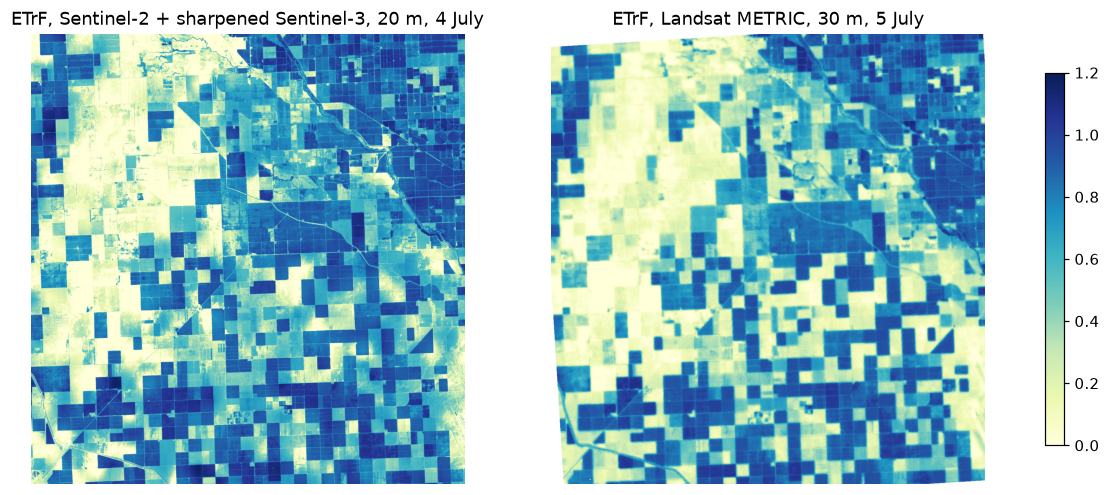

In [8]:
ndvi2 = seb.ndvi(s2.red, s2.nir).where(m2)  # NDVI
lai2 = seb.leaf_area_index(seb.savi(s2.red, s2.nir, L=0.1)).where(m2)  # LAI (METRIC SAVI curve)
alb2 = seb.albedo(s2.where(m2), sensor="sentinel2")  # Bonafoni and Sekertekin (2020) weights
dem2 = sd.dem_on(s2.red, SITE)  # elevation on the 20 m grid
res2, anc2, etr2 = metric_chain(lst_s2.where(m2), ndvi2, alb2, lai2, dem2, when3, m2, ref_daily.loc["2024-07-04", "etr"])  # METRIC at 20 m
ls_etrf = metric.etrf.rio.reproject_match(s2.red, resampling=Resampling.bilinear)  # Landsat ETrF on the 20 m grid
s_ = seb.compare_to_tower(res2.etrf, ls_etrf)  # Sentinel ETrF (4 July) against Landsat ETrF (5 July)
print(f"ETr: {etr2:.2f} mm/h at the SLSTR overpass, {ref_daily.loc['2024-07-04', 'etr']:.1f} mm for 4 July | "
      f"ETrF against Landsat: R2 {s_.r2:.2f}, bias {s_.bias:+.3f}, RMSE {s_.rmse:.3f}")  # agreement
cdl2 = sd.cdl_on(s2.red, SITE, 2024)  # crop map on the 20 m grid
crops = cdl2.where(m2).to_series().value_counts().index[:8]  # the 8 most common classes
display(pd.DataFrame({sd.cdl_name(c): {"Sentinel-2 + S3, 4 July": float(res2.etrf.where(cdl2 == c).median()),
                                        "Landsat, 5 July": float(ls_etrf.where(cdl2 == c).median())} for c in crops}).T.round(2))  # median ETrF per crop
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))  # two maps
for a_, v, t in zip(ax, [res2.etrf, ls_etrf], ["ETrF, Sentinel-2 + sharpened Sentinel-3, 20 m, 4 July", "ETrF, Landsat METRIC, 30 m, 5 July"]):  # both
    im = a_.imshow(v, cmap="YlGnBu", vmin=0, vmax=1.2); a_.set_title(t); a_.axis("off")  # map
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()  # shared scale

The 20 m ETrF map from Sentinel-2 and sharpened Sentinel-3 reproduces the Landsat field pattern of
the next day (R2 0.79, RMSE 0.16), and the medians of the irrigated crops agree within 0.07. Fallow
land differs most, with a median ETrF of 0.27 against 0.15, and rangeland 0.32 against 0.24.
Sharpening cannot reproduce the hottest extremes, so dry fields look a little cooler, and
METRIC turns that into some ET. The two do not have to match exactly: they are a day apart, at
slightly different times, with different reflectance and LST sensors. Combining Sentinel-2 and Sentinel-3 this
way fills the gaps between Landsat passes at field scale, which notebook 10 shows matters for
seasonal totals.

## Summary and exercises

- MODIS, Sentinel-3 and Landsat trade pixel size against revisit; at 1 km anchors are mixtures, so
  the calibration spans a narrower temperature range.
- METRIC on MODIS at 1 km reproduced the regional pattern of Landsat METRIC averaged to 1 km (R2
  0.53) but was 3.1 mm/day higher, because its cold anchor is a mixed pixel given 1.05 ETr.
- The data mining sharpener, tested on Landsat degraded to 990 m, halved the RMSE of bilinear
  interpolation (2.3 against 4.5 K) and, unsmoothed, conserves the coarse LST exactly.
- Sentinel-3 LST sharpened with Sentinel-2 to 20 m gave a METRIC ETrF map on a day without Landsat
  that matched the next day's Landsat pattern (R2 0.79), with higher ETrF over the driest fields.

**Exercises**

1. Repeat the Landsat sharpening test with `model="tree"` and `model="boosting"`, and with only NDVI
   as a predictor. Which predictors matter most?
2. Run METRIC on the Aqua afternoon overpass (`MYD11A1`). How does ETrF from 13:30 compare with the
   morning?
3. Sharpen Sentinel-3 with the 30 m Landsat reflectance of 5 July instead of Sentinel-2. Does the
   sensor of the predictors matter?
4. Find the next Sentinel-2 and Sentinel-3 pair after 5 July (9 July) and map ETrF for that day.
   How much did the fields change in four days?